# Fast CD and conditional squeezing: minimum swap time 200 ns

The sideband coupling must satisfy $|g(t)|\leq g_{\max}=\pi/(2\times
0.200\,\mu\mathrm{s})=7.85398\,\mathrm{rad}/\mu\mathrm{s}$ at **every sample**.
The check bounds the magnitude $\sqrt{I^2+Q^2}$, including transitions and the
modeled RFDC response. Every qubit pi envelope is the calibrated 30 ns Hann.
The ideal model uses a perfect two-level qubit, resonant JC, no loss or chi.

**Current verified results:** CD(beta=1) in **300 ns at 99.2720%**, with peak
coupling equivalent to a **200.39 ns swap**. Smooth pump I/Q changes take
10 ns. A fixed-pump-phase version gives **310 ns at 99.0141%**. Conditional
squeezing of **8 dB takes 3.61 us at 99.0724%**, using only weaker coupling.

The earlier 260 ns CD needed about 35 ns swap coupling. It is **excluded**
under this hardware constraint; its outputs are retained in the archive.
Gate time here is the programmed device-envelope duration. Both channels
share one time axis; common buffer/DAC latency is not added to the duration.

Fidelity is coherent process fidelity on all 18 qubit g/e × Fock n=0..8 input
states, with relative phases and leakage retained. It is not a worst-input
guarantee. Output and target cutoffs grow automatically.

In [1]:
# Locate code/ when this notebook is opened from notebooks/ or archive/.
from pathlib import Path as _Path
import sys as _sys
_project=next(p for p in [_Path.cwd(),*_Path.cwd().parents]
              if (p/'code/project_paths.py').is_file())
if str(_project/'code') not in _sys.path:
    _sys.path.insert(0,str(_project/'code'))
from project_paths import ROOT as PROJECT_ROOT, CODE, NOTEBOOKS


import os
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['OMP_NUM_THREADS']='1'
import json,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import cd_trains as cd
import hardware_check as hw
from capped_cd_study import OUT,MAX_G
from verify_swap200 import source_and_arrays
FIGURES=OUT/'figures';FIGURES.mkdir(exist_ok=True)
def read(name):return json.loads((OUT/name).read_text())
def certificate(name):return read('verified/'+name+'.json')
def finish(name):
    plt.savefig(FIGURES/(name+'.png'),dpi=160,bbox_inches='tight');plt.show()
manifest=read('verified/manifest.json')
assert manifest['records']==14 and manifest['columns']==252 and manifest['minimum_swap_ns']==200
records=manifest['results']
for r in records:assert r['peak_g_rad_per_us']<=MAX_G and r['actual_min_swap_ns']>=200
print('VERIFIED:',manifest['records'],'records;',manifest['columns'],'inputcolumns;',
      manifest['independent_amplitudes'],'independentamplitudes;allpeakcouplingswithin200nslimit')
names=['edge_n10_gap0_phase1','cd_n10_gap0_phase0','cd_n12_gap0_phase0','squeeze_8db']
display(pd.DataFrame([{k:r[k] for k in ['name','command_us','fidelity','actual_min_swap_ns','qubit_frame_Rz']}
                      for r in map(certificate,names)]))


VERIFIED: 14 records; 252 inputcolumns; 56448 independentamplitudes;allpeakcouplingswithin200nslimit


,name,command_us,fidelity,actual_min_swap_ns,qubit_frame_Rz
0,edge_n10_gap0_phase1,0.30,0.992720,200.389462,0.000000
1,cd_n10_gap0_phase0,0.31,0.990141,201.705106,0.000000
2,cd_n12_gap0_phase0,0.37,0.995219,262.682681,0.000000
3,squeeze_8db,3.61,0.990724,281.528090,2.443874


## 1. Construction and what was optimized

At the CD pump quadrature, JC and its qubit-X conjugate obey

$$A=\tfrac12(\sigma_xP-\sigma_yX),\quad B=\sigma_xA\sigma_x,
\quad A+B=\sigma_xP,\qquad
\mathrm{CD}(\beta)=e^{-i\beta\sigma_xP},$$

where $X=a+a^\dagger$ and $P=i(a^\dagger-a)$. Repeated JC/anti-JC alternation
is the seed. Finite qubit pulses leave unwanted terms, so simply increasing
coupling or changing a formal Trotter order does not fix their evolution.

The new search keeps 30 ns pi pulses and adjusts **the qubit axes plus two
smooth pump coefficients per cell**. Those coefficients weight different
parts of the finite qubit rotation. The phase-control family also adjusts
their complex directions. Interpolation takes 10 ns; no individual waveform
sample is an optimization variable. This is a Trotter-seeded finite-pulse
correction, without an unverified claim of a particular higher order.

Initial phase words come from the previous binary JC/anti-JC search. Fixed
phase and variable phase are tested at the same pulse counts and gaps. The
300 ns case places the outer 5 ns pump ramps inside the first/last qubit
envelopes, removing the separate 10 ns buffer. Ten pi pulses then occupy the
whole 300 ns. All simultaneous evolution is included in the propagation.

Every candidate obeys the peak limit during optimization. For the linear
map K from complex pump coefficients to filtered samples,

$$|(Kz)_j|\leq\max_k|z_k|\sum_k|K_{jk}|.$$

The coefficient radius uses this bound plus an int16 rounding margin. This
prevents either changing phase or filtering from hiding an excessive peak.
The gradient was checked in six finite-difference directions. The local
search evaluated 12 candidates; this is not a global minimum-time proof.

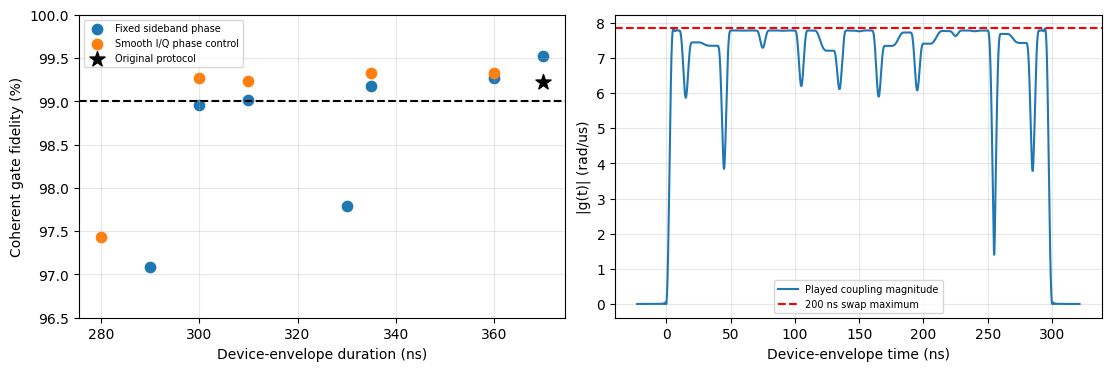

Selected CD: edge_n10_gap0_phase1 actualminimumswapns 200.3894620858736


In [2]:

cdrows=[r for r in records if r['gate']=='cd']
fig,axes=plt.subplots(1,2,figsize=(11,3.6),constrained_layout=True)
for constant,label in [(True,'Fixed sideband phase'),(False,'Smooth I/Q phase control')]:
    rows=[r for r in cdrows if r['pump_phase_constant']==constant and r['name']!='baseline_cd']
    axes[0].scatter([r['command_us']*1000 for r in rows],[100*r['fidelity'] for r in rows],s=55,label=label)
axes[0].scatter([370],[100*certificate('baseline_cd')['fidelity']],marker='*',s=130,c='k',label='Original protocol')
axes[0].axhline(99,c='k',ls='--');axes[0].set(xlabel='Device-envelope duration (ns)',ylabel='Coherent gate fidelity (%)',ylim=(96.5,100))
axes[0].legend(fontsize=7);axes[0].grid(alpha=.3)
selected=manifest['selected']['cd']
record,(qraw,sraw,qf,sf,words),model=source_and_arrays(selected)
delay=np.argmax(abs(hw.rfdc_interpolate(np.array([1.]))))*cd.DT/8
timefine=(np.arange(len(sf))*cd.DT/8-delay)*1000
axes[1].plot(timefine,abs(sf),label='Played coupling magnitude')
axes[1].axhline(MAX_G,c='r',ls='--',label='200 ns swap maximum')
axes[1].set(xlabel='Device-envelope time (ns)',ylabel='|g(t)| (rad/us)')
axes[1].legend(fontsize=7);axes[1].grid(alpha=.3)
finish('duration_and_peak_limit')
print('Selected CD:',selected,'actualminimumswapns',certificate(selected)['actual_min_swap_ns'])


## 2. Literal pulse sequence, I/Q and total magnitude

The tables show all ten physical qubit axes and all twenty pump coefficients.
Every qubit pulse lasts 30 ns; there are no gaps in the 300 ns recipe. Two
pump coefficients per cell nominally occupy its first/second 15 ns. Adjacent
coefficients blend with a 10 ns quintic Cartesian interpolation,

$$z(u)=[1-h(u)]z_0+h(u)z_1,\qquad h(u)=10u^3-15u^4+6u^5.$$

That blend occupies the last 5 ns and first 5 ns of neighboring intervals.
The outer amplitude ramps take 5 ns each. The complete qubit and pump I/Q
words are exported alongside the
[qubit sequence](../../runs/swap200/verified/edge_n10_gap0_phase1_sequence.csv) and
[pump coefficient table](../../runs/swap200/verified/edge_n10_gap0_phase1_pump_knots.csv).
There is no final qubit frame correction for this CD gate.

Magnitude means $|I+iQ|=\sqrt{I^2+Q^2}$ separately for each channel. The plot
removes the common RFDC group delay only to align the display; the complete
filtered shapes are propagated. It also shows the programmed I/Q samples.

,pulse,start_ns,duration_ns,qubit_DAC_deg
0,1,0.0,30.0,327.32768
1,2,30.0,30.0,346.54646
2,3,60.0,30.0,203.12639
3,4,90.0,30.0,217.05028
4,5,120.0,30.0,34.82734
5,6,150.0,30.0,327.36464
6,7,180.0,30.0,140.17140
7,8,210.0,30.0,157.12774
8,9,240.0,30.0,39.00029
9,10,270.0,30.0,55.81423


,knot,g_rad_per_us,pump_DAC_deg,transition_ns
0,1,7.785407,259.496024,10
1,2,7.445593,338.500637,10
2,3,7.350645,345.538532,10
3,4,7.785407,226.651878,10
4,5,7.785407,230.662345,10
5,6,7.785407,271.663364,10
6,7,7.785407,265.832345,10
7,8,7.785407,191.476194,10
8,9,7.210633,201.289951,10
9,10,7.785407,271.546453,10


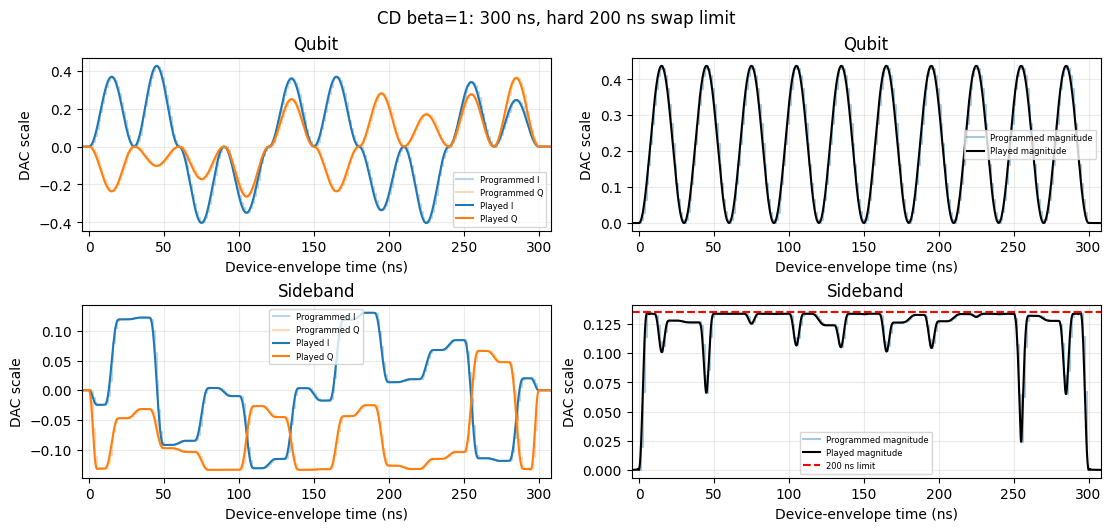

In [3]:

display(pd.read_csv(OUT/'verified'/f'{selected}_sequence.csv').round(5))
display(pd.read_csv(OUT/'verified'/f'{selected}_pump_knots.csv').round(7))
qs,ss=hw.dac_scales(.6)
def waveform_figure(arrays,title,duration,name):
    qr,sr,q,s,w=arrays
    physical=[q.conj()/(np.pi/cd.PI_TIME)*qs,s/(np.pi/(2*.6))*ss]
    fig,axes=plt.subplots(2,2,figsize=(11,5.2),constrained_layout=True)
    for row,(key,channel,z) in enumerate(zip(['qubit','sideband'],['Qubit','Sideband'],physical)):
        raw=hw.sample_to_complex(w[key]);t=np.arange(len(raw))*cd.DT*1000
        tf=(np.arange(len(z))*cd.DT/8-delay)*1000
        axes[row,0].step(t,raw.real,where='post',alpha=.3,c='C0',label='Programmed I')
        axes[row,0].step(t,raw.imag,where='post',alpha=.3,c='C1',label='Programmed Q')
        axes[row,0].plot(tf,z.real,c='C0',label='Played I');axes[row,0].plot(tf,z.imag,c='C1',label='Played Q')
        axes[row,1].step(t,abs(raw),where='post',alpha=.4,label='Programmed magnitude')
        axes[row,1].plot(tf,abs(z),c='k',label='Played magnitude')
        if row==1:axes[row,1].axhline(ss*MAX_G/(np.pi/(2*.6)),c='r',ls='--',label='200 ns limit')
        for ax in axes[row]:
            ax.set(title=channel,xlabel='Device-envelope time (ns)',ylabel='DAC scale',xlim=(-5,duration+8))
            ax.grid(alpha=.25);ax.legend(fontsize=6)
    fig.suptitle(title);finish(name)
cdarrays=(qraw,sraw,qf,sf,words)
waveform_figure(cdarrays,'CD beta=1: 300 ns, hard 200 ns swap limit',300,'CD_IQ_and_magnitude')


## 3. Fixed-sequence strength sensitivity

This curve holds timing, qubit phases and the relative pump pattern fixed,
and scales only its overall coupling downward. The target remains beta=1.
It is a calibration sensitivity curve, not a separately reoptimized envelope.
Only allowed strengths are shown. All 18 input columns are propagated and
compared at two output cutoffs for every point.

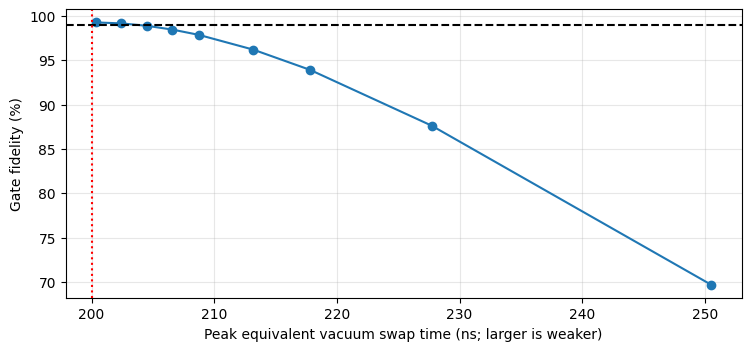

STRENGTH CHECK:9points;162columns; 31104 cutoffcomparisonamplitudes


In [4]:

points=[];count=0
for factor in [1.,.99,.98,.97,.96,.94,.92,.88,.8]:
    previous=None
    for levels in [64,96]:
        space=cd.Space(levels,9);initial=np.eye(2*levels,dtype=complex)[:,space.inputs]
        T=cd.target_columns(space,'cd',1.)
        V=hw.propagate(qf,sf*factor,initial,cd.DT/8,order=8,fast=True)
        if previous is not None:
            pad=np.zeros_like(V);pad[:len(previous)]=previous
            difference=float(max(np.linalg.norm(V-pad,axis=0)));assert difference<1e-9
            count+=V.size
        previous=V
    peak=max(abs(sf))*factor
    assert peak<=MAX_G
    points.append(dict(minimum_swap_ns=1000*np.pi/(2*peak),fidelity=float(abs(np.vdot(T,V)/18)**2),
                       cutoff_change=difference))
assert len(points)==9 and count==31104
pd.DataFrame(points).to_csv(OUT/'strength_sensitivity.csv',index=False)
fig,ax=plt.subplots(figsize=(7.4,3.4),constrained_layout=True)
ax.plot([p['minimum_swap_ns'] for p in points],[100*p['fidelity'] for p in points],'o-')
ax.axhline(99,c='k',ls='--');ax.axvline(200,c='r',ls=':')
ax.set(xlabel='Peak equivalent vacuum swap time (ns; larger is weaker)',ylabel='Gate fidelity (%)')
ax.grid(alpha=.3);finish('CD_allowed_strength_sensitivity')
print('STRENGTH CHECK:9points;162columns;',count,'cutoffcomparisonamplitudes')


## 4. Conditional squeezing remains within the limit

The fixed target is

$$S_z(r)=\exp[\tfrac r2\sigma_z(a^2-a^{\dagger2})],\qquad r=8\ln(10)/20.$$

The 120-pulse, 3.61 us construction gives 99.0724% coherent gate fidelity.
It never approaches the sideband limit: the largest filtered coupling is
equivalent to about a 282 ns swap. Every qubit pi pulse is 30 ns and every
pump transition is the same 10 ns Cartesian interpolation used above.

The [complete squeezing pulse table](../../runs/higher_order_cd/verified/compressed_squeeze_n120_sequence.csv)
lists all qubit and pump phases. Apply the **one common final qubit Rz** in
the results table after the complete train; it is included in the fidelity.
This accepted sequence came from systematic pulse-pair removal and phase
correction of the earlier 128-pulse gate. The attempted 112- and 96-pulse
constructions failed 99%; their saved results are not recommendations.

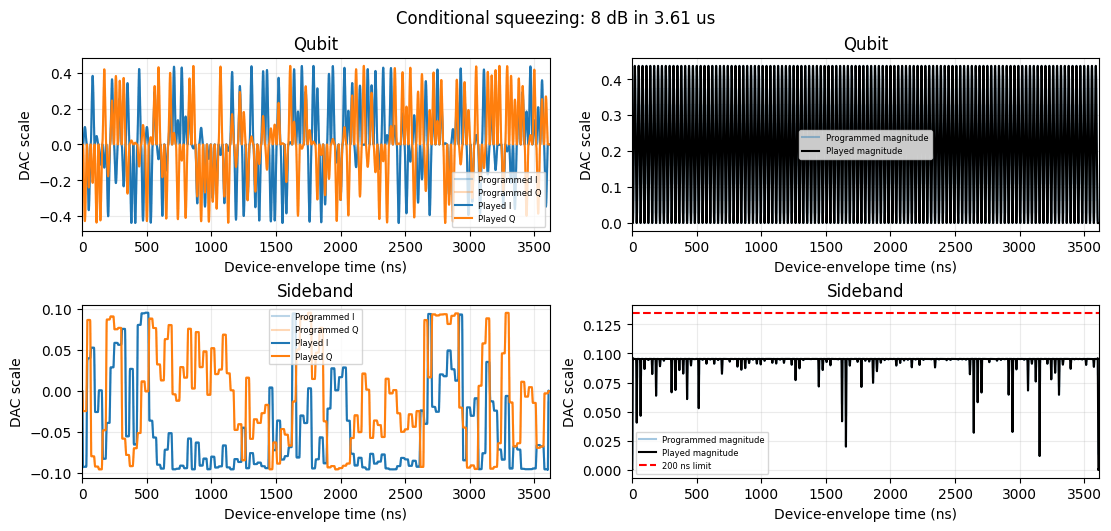

Squeeze minimum equivalent swap time (ns): 281.52809032491956
Final qubit Rz after the whole train (rad): 2.443874216706827


In [5]:

sqrecord,sqarrays,sqmodel=source_and_arrays('squeeze_8db')
sqcert=certificate('squeeze_8db')
waveform_figure(sqarrays,'Conditional squeezing: 8 dB in 3.61 us',3610,'squeezing_IQ_and_magnitude')
print('Squeeze minimum equivalent swap time (ns):',sqcert['actual_min_swap_ns'])
print('Final qubit Rz after the whole train (rad):',sqcert['qubit_frame_Rz'])


## 5. Individual input diagnostics

These state fidelities show where the error is concentrated among the 18
basis inputs. They do not replace the coherent process metric: relative
phases between different inputs also count in the reported gate fidelity.
Leakage is retained throughout; no state is renormalized into the input space.

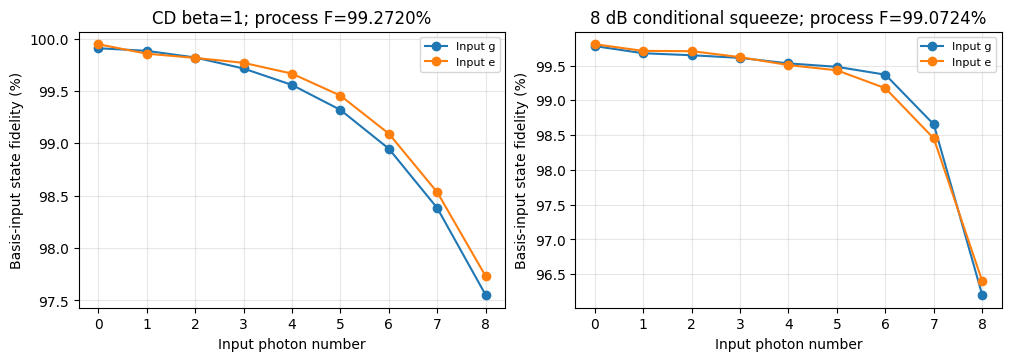

In [6]:

fig,axes=plt.subplots(1,2,figsize=(10,3.5),constrained_layout=True)
for ax,name,title in zip(axes,[selected,'squeeze_8db'],['CD beta=1','8 dB conditional squeeze']):
    data=np.load(OUT/'verified'/f'{name}_columns.npz')
    overlaps=np.sum(data['target'].conj()*data['output'],axis=0)
    F=float(abs(overlaps.mean())**2)
    assert abs(F-certificate(name)['fidelity'])<1e-13
    for offset,label in [(0,'Input g'),(9,'Input e')]:
        ax.plot(np.arange(9),100*abs(overlaps[offset:offset+9])**2,'o-',label=label)
    ax.set(title=f'{title}; process F={100*F:.4f}%',xlabel='Input photon number',ylabel='Basis-input state fidelity (%)')
    ax.grid(alpha=.3);ax.legend(fontsize=8)
finish('individual_input_checks')


## 6. Fresh independent simulation

The final cell independently evolves all 18 CD columns at 128 oscillator
levels and both squeezing boundary inputs g8/e8 at 384 levels. It compares
complex amplitudes against the saved certificates. The earlier full
squeezing certificate separately checked every column and target cutoff.

The 12 locally fitted CD candidates and two references have 252 verified
input columns and 56,448 independent amplitude comparisons. The 200 ns
limit is an explicit peak-norm assertion on every waveform. No coupler or
board experiment is invoked, and no global optimality claim is made.

FRESH CD:18columns; 4608 amplitudes;maxdifference 6.149539670923232e-16 F 0.9927202573459256


FRESH SQUEEZE:2boundaryinputs; 1536 amplitudes;maxdifference 2.2903921347163597e-15


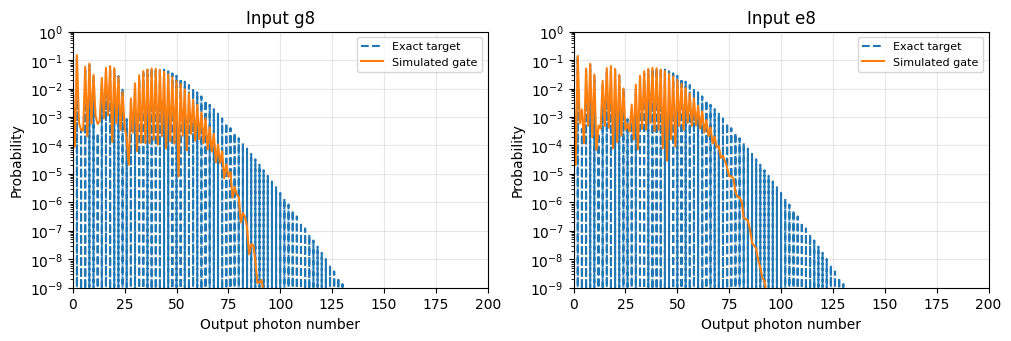

In [7]:

space=cd.Space(128,9);initial=np.eye(256,dtype=complex)[:,space.inputs]
replay=hw.propagate(qf,sf,initial,cd.DT/8,order=16)
target=cd.target_columns(space,'cd',1.)
saved=np.load(OUT/'verified'/f'{selected}_columns.npz')['output']
pad=np.zeros_like(replay);pad[:len(saved)]=saved
error=float(np.max(abs(replay-pad)));F=float(abs(np.vdot(target,replay)/18)**2)
assert replay.shape==(256,18) and error<1e-10 and F>.99
assert max(abs(sf))<=MAX_G
print('FRESH CD:18columns;',replay.size,'amplitudes;maxdifference',error,'F',F)
qr,sr,qSq,sSq,wSq=sqarrays
spaceSq=cd.Space(384,9);inputsSq=np.eye(768,dtype=complex)[:,[16,17]]
replaySq=hw.propagate(qSq,sSq,inputsSq,cd.DT/8,order=16)
replaySq*=np.exp(-1j*sqcert['qubit_frame_Rz']*spaceSq.z/2)[:,None]
targetSq=cd.target_columns(spaceSq,'squeeze',cd.R_8DB)[:,[8,17]]
savedSq=np.load(OUT/'verified/squeeze_8db_columns.npz')['output'][:,[8,17]]
padSq=np.zeros_like(replaySq);padSq[:len(savedSq)]=savedSq
errorSq=float(np.max(abs(replaySq-padSq)))
assert replaySq.shape==(768,2) and errorSq<1e-10 and max(abs(sSq))<=MAX_G
print('FRESH SQUEEZE:2boundaryinputs;',replaySq.size,'amplitudes;maxdifference',errorSq)
fig,axes=plt.subplots(1,2,figsize=(10,3.3),constrained_layout=True)
for j,ax in enumerate(axes):
    a=(abs(replaySq[:,j])**2).reshape(-1,2).sum(axis=1)
    b=(abs(targetSq[:,j])**2).reshape(-1,2).sum(axis=1)
    ax.semilogy(b,'--',label='Exact target');ax.semilogy(a,label='Simulated gate')
    ax.set(title=['Input g8','Input e8'][j],xlabel='Output photon number',ylabel='Probability',xlim=(0,200),ylim=(1e-9,1))
    ax.grid(alpha=.3);ax.legend(fontsize=8)
finish('fresh_squeezing_boundary_inputs')
